In [ ]:
import pandas as pd
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    KFold,
    StratifiedKFold,
)
from sklearn.metrics import root_mean_squared_error
from sklearn.ensemble import RandomForestRegressor
import numpy as np
from recipe import output_cross_val_results, TrainValidationTest

In [ ]:
df_epi_raw = pd.read_csv("data/epi_r.csv", sep=",")
df_epi_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 20052 entries, 0 to 20051
Columns: 680 entries, title to turkey
dtypes: float64(679), str(1)
memory usage: 104.0 MB


In [ ]:
from recipe import DataCleaner, FeatureExtractor

from sklearn.pipeline import Pipeline

preprocessing_pipe = Pipeline(
    [("data_cleaner", DataCleaner()), ("feature_extractor", FeatureExtractor())]
)

df_epi = preprocessing_pipe.fit_transform(df_epi_raw)

[DataCleaner] After drop duplicates. Shape = (20052, 680)
[DataCleaner] After drop duplicates. Shape = (18235, 680)
[DataCleaner] Before memory optimization
<class 'pandas.DataFrame'>
Index: 18235 entries, 0 to 20051
Columns: 680 entries, title to turkey
dtypes: float64(679), str(1)
memory usage: 94.7 MB
None

[DataCleaner] After memory optimization
<class 'pandas.DataFrame'>
Index: 18235 entries, 0 to 20051
Columns: 680 entries, title to turkey
dtypes: float64(5), int8(674), str(1)
memory usage: 12.7 MB
None

[DataCleaner] Final ingredients count: 345
[FeatureExtractor] Feature extracted. (18235, 346)


In [ ]:
df_epi.columns

,rating,almond,amaretto,anchovy,anise,apple,apple juice,apricot,artichoke,arugula,...,watercress,watermelon,whiskey,white wine,wild rice,wine,yogurt,yuca,zucchini,turkey
0,2.500,0,0,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
1,4.375,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,3.750,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,5.000,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,3.125,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20047,3.125,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
20048,4.375,0,0,0,0,0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0
20049,4.375,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
20050,4.375,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [ ]:
y = df_epi['rating']
X = df_epi.drop(columns=['rating'])
y.shape, X.shape

((18235,), (18235, 345))

<Axes: ylabel='Frequency'>

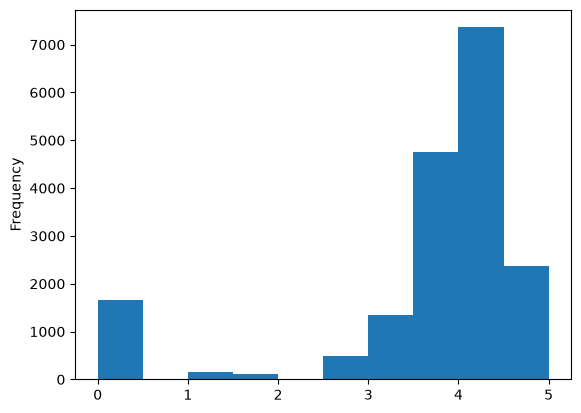

In [ ]:
from recipe import TrainValidationTest

tvt = TrainValidationTest()
X_train, X_valid, X_test, y_train, y_valid, y_test = tvt.get_datasets(X, y)
y.plot.hist()

<Axes: xlabel='rating'>

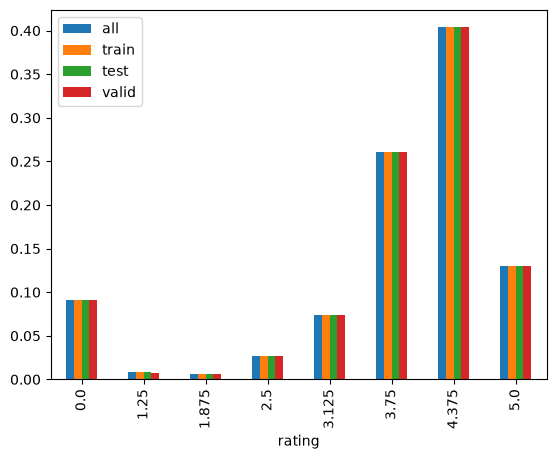

In [ ]:
def norm_value_counts(vals):
    return vals.value_counts(normalize=True).sort_index()


pd.DataFrame(
    {
        "all": norm_value_counts(y),
        "train": norm_value_counts(y_train),
        "test": norm_value_counts(y_test),
        "valid": norm_value_counts(y_valid),
    }
).plot.bar()

In [ ]:
cv_strategy = KFold(n_splits=5, shuffle=True, random_state=42)

### LinearRegression 

In [ ]:
lin_reg = LinearRegression()
lin_reg.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](345,)","[ 0.13, 0.33,-0.15,..., 0.55,-0.06, 0.3 ]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](345,)","['almond','amaretto','anchovy',...,'yuca','zucchini','turkey']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,3.431
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,345
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(343)


In [ ]:
cvs_log_reg = cross_val_score(lin_reg, X_train, y_train, scoring='neg_root_mean_squared_error', cv=cv_strategy)
output_cross_val_results(cvs_log_reg, lin_reg.__class__.__name__)

Cross-validation sore of mode LinearRegression
mean = 1.28, std=0.01


In [ ]:
from sklearn.linear_model import Lasso

In [ ]:
from sklearn.linear_model import LassoCV

# LassoCV автоматически переберет сетку alpha и выберет лучшую
lasso_cv = LassoCV(cv=5, random_state=42)
lasso_cv.fit(X_train, y_train)

print(f"Оптимальный alpha: {lasso_cv.alpha_}")

Оптимальный alpha: 0.0007625769983485987


In [ ]:
lasso_clf = Lasso(alpha=lasso_cv.alpha_)
cvs_lasso = cross_val_score(
    lasso_clf, X_train, y_train, scoring="neg_root_mean_squared_error", cv=cv_strategy
)
output_cross_val_results(cvs_lasso, lasso_clf.__class__.__name__)

Cross-validation sore of mode Lasso
mean = 1.27, std=0.01


In [ ]:
lasso_clf.fit(X_train, y_train)
lasso_coef = pd.DataFrame({'coef': np.abs(lasso_clf.coef_), 'name': lasso_clf.feature_names_in_})
lasso_coef.sort_values(by='coef', ascending=False).to_csv('data/lasso_coef.csv', index=False)

In [ ]:
lasso_cols_importatant = lasso_coef[lasso_coef['coef'] != 0]['name']
lasso_cols_importatant

0          almond
4           apple
6         apricot
8         arugula
10      asparagus
          ...    
337       whiskey
338    white wine
341        yogurt
343      zucchini
344        turkey
Name: name, Length: 172, dtype: str

In [ ]:
cvs_log_reg = cross_val_score(lin_reg, X_train[lasso_cols_importatant], y_train, scoring='neg_root_mean_squared_error', cv=cv_strategy)

In [ ]:
from sklearn.ensemble import RandomForestRegressor

rf_clf = RandomForestRegressor(random_state=21, n_jobs=-1)
cvs_rf_clf = cross_val_score(
    rf_clf,
    X_train,
    y_train,
    scoring="neg_root_mean_squared_error",
    cv=cv_strategy,
    n_jobs=-1,
)
output_cross_val_results(cvs_rf_clf, rf_clf.__class__.__name__)

Cross-validation sore of mode RandomForestRegressor
mean = 1.39, std=0.01


In [ ]:
from sklearn.model_selection import GridSearchCV
from recipe import ModelSelectionRegression
from sklearn.linear_model import Ridge, Lasso
from sklearn.ensemble import (
    GradientBoostingRegressor,
    HistGradientBoostingRegressor,
    RandomForestRegressor,
    StackingRegressor,
)
cv = 5  # 5

lin_reg_param = {"fit_intercept": [True]}
lin_reg = LinearRegression()
lin_reg_cv = GridSearchCV(
    lin_reg,
    lin_reg_param,
    n_jobs=-1,
    cv=cv,
    scoring="neg_mean_squared_error",
)

ridge_param = {
    "alpha": [1000, 100, 10, 1, 0.1, 0.01, 0.001, 0.0001],
    "solver": ["svd", "cholesky", "lsqr", "sparse_cg", "sag", "saga"],
}
ridge = Ridge()

ridge_cv = GridSearchCV(
    ridge,
    ridge_param,
    n_jobs=-1,
    cv=cv,
    scoring="neg_mean_squared_error",
)
lasso_param = {
    "alpha": [1000, 100, 10, 1, 0.1, 0.01, 0.001, 0.0001],
}
lasso = Lasso(random_state=21)
lasso_cv = GridSearchCV(
    lasso,
    lasso_param,
    n_jobs=-1,
    cv=cv,
    scoring="neg_mean_squared_error",
)

rf = RandomForestRegressor(random_state=21, n_jobs=-1)
rf_grid = {
    "n_estimators": [400, 500, 750, 1000],  # Number of trees in the forest
    "max_depth": [None, 10, 20, 30, 40],  # Maximum depth of the trees
    "min_samples_split": [2, 5, 10],  # Minimum samples required to split a node
    "min_samples_leaf": [1, 2, 4],  # Minimum samples required at each leaf node
    "max_features": ["sqrt", "log2"],  # Number of features to consider at each split
}

# 4. Set up GridSearchCV with 5-fold cross-validation
rf_cv = GridSearchCV(
    estimator=rf,
    param_grid=rf_grid,
    cv=cv,
    scoring="neg_mean_squared_error",
    n_jobs=-1,
)


gbr = GradientBoostingRegressor(random_state=42)
gbr_params = {"n_estimators":[150, 200, 300], 
              "learning_rate": [0.05, 0.1], "max_depth": [3, 5]},
gbr_cv = GridSearchCV(
    estimator=gbr,
    param_grid=gbr_params,
    cv=cv,
    scoring="neg_mean_squared_error",
    n_jobs=-1,
)

hgbr = HistGradientBoostingRegressor(random_state=42)
hgbr_params = {
            "max_iter": [200, 300],
            "learning_rate": [0.05, 0.1, 0.2],
            "max_depth": [3, 5, None],
        }
hgbr_cv = GridSearchCV(
    estimator=hgbr,
    param_grid=hgbr_params,
    cv=cv,
    scoring="neg_mean_squared_error",
    n_jobs=-1,
)


In [ ]:
params = [lin_reg_cv, ridge_cv, lasso_cv, rf_cv, gbr_cv, hgbr_cv]

ms_reg = ModelSelectionRegression(params)
ms_reg.choose(X_train, y_train, X_valid, y_valid)

Estimator: LinearRegression


100%|██████████| 1/1 [00:02<00:00,  2.54s/it]


Best params: {'fit_intercept': True}
Best training RMSE: 1.281
Validation set RMSE score for best params: 1.28

Estimator: Ridge


100%|██████████| 48/48 [05:22<00:00,  6.72s/it]


Best params: {'alpha': 10, 'solver': 'lsqr'}
Best training RMSE: 1.265
Validation set RMSE score for best params: 1.28

Estimator: Lasso


100%|██████████| 8/8 [00:02<00:00,  3.34it/s]


... (4 outputs left out)

Best params: {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 300}
Best training RMSE: 1.270
Validation set RMSE score for best params: 1.29

Estimator: HistGradientBoostingRegressor


100%|██████████| 18/18 [06:24<00:00, 21.35s/it]


Best params: {'learning_rate': 0.1, 'max_depth': 5, 'max_iter': 200}
Best training RMSE: 1.265
Validation set RMSE score for best params: 1.27

Classifier with best validation set RMSE: GridSearchCV(cv=5,
             estimator=RandomForestRegressor(max_depth=40, max_features='log2',
                                             min_samples_leaf=4,
                                             min_samples_split=10,
                                             n_estimators=1000, n_jobs=-1,
                                             random_state=21),
             n_jobs=-1,
             param_grid={'max_depth': [None, 10, 20, 30, 40],
                         'max_features': ['sqrt', 'log2'],
                         'min_samples_leaf': [1, 2, 4],
                         'min_samples_split': [2, 5, 10],
                         'n_estimators': [400, 500, 750, 1000]},
             scoring='neg_mean_squared_error')


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestR...ndom_state=21)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [None, 10, ...], 'max_features': ['sqrt', 'log2'], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 5, ...], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support f

In [ ]:
pd.DataFrame(ms_reg.model_results).T.sort_values(by='valid_score', ascending=True)

,name,params,valid_score
3,"GridSearchCV(cv=5,\n estimator=Ran...","{'max_depth': None, 'max_features': 'sqrt', 'm...",1.259534
2,"GridSearchCV(cv=5, estimator=Lasso(alpha=0.000...",{'alpha': 0.001},1.263638
1,"GridSearchCV(cv=5, estimator=Ridge(alpha=0.000...","{'alpha': 10, 'solver': 'lsqr'}",1.264805
5,"GridSearchCV(cv=5,\n estimator=His...","{'learning_rate': 0.1, 'max_depth': 5, 'max_it...",1.265351
4,"GridSearchCV(cv=5,\n estimator=Gra...","{'learning_rate': 0.05, 'max_depth': 3, 'n_est...",1.269831
0,"GridSearchCV(cv=5, estimator=LinearRegression(...",{'fit_intercept': True},1.280828


In [ ]:
rf_params = pd.DataFrame(ms_reg.model_results).T.sort_values(by='valid_score', ascending=True).iloc[0].params
rf_params

{'max_depth': None,
 'max_features': 'sqrt',
 'min_samples_leaf': 2,
 'min_samples_split': 10,
 'n_estimators': 1000}

In [ ]:
rf_clf = RandomForestRegressor(**rf_params, random_state=21, n_jobs=-1)

In [ ]:
X_train_valid = pd.concat([X_train, X_valid], axis=0)
X_train_valid.shape, X_train.shape, X_valid.shape

((14588, 345), (11670, 345), (2918, 345))

In [ ]:
y_train_valid = pd.concat([y_train, y_valid])
y_train_valid.shape, y_train.shape, y_test.shape

((14588,), (11670,), (3647,))

In [ ]:
rf_clf.fit(X_train_valid, y_train_valid)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",1000
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",10
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",2
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",21
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.

In [ ]:
rmse_res = root_mean_squared_error(y_test, rf_clf.predict(X_test))
rmse_res

1.2713903560555384

In [ ]:
import joblib

joblib.dump(rf_clf, f'data/rf_clf_rmse_{rmse_res}.sav')

['data/rf_clf_rmse_1.2713903560555384.sav']

In [ ]:
assert 1 == 0

AssertionError: 